# Milestone 1 — Transportation Dataset: Loading, EDA and Cleaning

##  Dataset overview

| Item | Details |
|---|---|
| Dataset | **Serious Injury Response, Tracking & Analysis Program (SIRTA)** — NYC DOT (catalog T4) |
| Link | https://data.cityofnewyork.us/Transportation/Serious-Injury-Response-Tracking-Analysis-Program-/xeqp-qz8h |
| Dataset ID | `xeqp-qz8h` |
| Unit of observation | One row = one crash with at least one **severe injury or fatality** (from January 2022) |
| Size | ~13.7k rows x 23 columns (meets the 9-column minimum) |
| Geographic attributes | Borough, police precinct, community board, council district, census tract (2020), NTA (2020), ZIP, latitude/longitude, street/address |
| Temporal attributes | Crash date and crash time |
| Why this dataset | It contains **severity** (severe injuries and fatalities), not just crash counts, and it has several geographic keys (community board, census tract, ZIP, lat/lon). That gives us several ways to link it to the DOB NOW housing filings. |
| Known issues to check | Blank "orphan" rows, ZIP often blank, missing coordinates, text-typed dates/times, repeated collision IDs, highly skewed counts |


### Prompts used
"Provide the code in blocks for: select and load the transportation dataset, perform EDA, explore columns/types/missing/duplicates/outliers, clean and standardize, document decisions, and develop 2 research questions and 2 visualizations."


## Setup

In [62]:
import re
import warnings
from datetime import date

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from scipy import stats
from scipy.spatial import cKDTree
from IPython.display import display

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)
# ---------------- Configuration----------------
SIRTA_ID = "xeqp-qz8h"
BASE_URL = "https://data.cityofnewyork.us/api/views/{}/rows.csv?accessType=download"
HOUSING_CLEAN_FILE = "housing_clean.csv"
SIRTA_CLEAN_FILE = "sirta_clean.csv"

NYC_LAT_RANGE = (40.45, 40.95)
NYC_LON_RANGE = (-74.30, -73.65)
PANEL_START = "2022-01"
MAX_CASUALTIES_PER_CRASH = 20                   # severe injuries + deaths exceeds than this in one crash is flagged
MIN_CRASHES_PER_DISTRICT = 50                   # districts with fewer located crashes give unstable shares
ASSIGN_MAX_M = 300                              # a crash farther than this from any housing filing stays unassigned

BOROUGH_MAP = {
    "MANHATTAN": "MANHATTAN", "NEW YORK": "MANHATTAN", "MN": "MANHATTAN", "1": "MANHATTAN",
    "BRONX": "BRONX", "THE BRONX": "BRONX", "BX": "BRONX", "2": "BRONX",
    "BROOKLYN": "BROOKLYN", "BKLYN": "BROOKLYN", "BK": "BROOKLYN", "KINGS": "BROOKLYN", "3": "BROOKLYN",
    "QUEENS": "QUEENS", "QN": "QUEENS", "4": "QUEENS",
    "STATEN ISLAND": "STATEN ISLAND", "SI": "STATEN ISLAND", "RICHMOND": "STATEN ISLAND", "5": "STATEN ISLAND",
}
BOROUGH_CODE = {1: "MANHATTAN", 2: "BRONX", 3: "BROOKLYN", 4: "QUEENS", 5: "STATEN ISLAND"}
BOROUGH_ABBR = {"MANHATTAN": "MN", "BRONX": "BX", "BROOKLYN": "BK", "QUEENS": "QN", "STATEN ISLAND": "SI"}
CD_COUNT = {1: 12, 2: 12, 3: 18, 4: 14, 5: 3}   # community districts per borough (code = borough digit + 2-digit CD)
STREET_SUFFIX = {"AVE": "AVENUE", "AV": "AVENUE", "ST": "STREET", "BLVD": "BOULEVARD", "RD": "ROAD",
                 "PKWY": "PARKWAY", "DR": "DRIVE", "PL": "PLACE"}
STREET_SUFFIX_PATTERN = r"\b(" + "|".join(STREET_SUFFIX) + r")$"

def normalize_community_board(series): #making sure that values followa the numbering system
    cb = pd.to_numeric(series, errors="coerce")
    boro_digit, cd_number = cb // 100, cb % 100
    valid = boro_digit.isin(list(CD_COUNT)) & (cd_number >= 1) & (cd_number <= boro_digit.map(CD_COUNT))
    return cb.where(valid).astype("Int64")

## Load the transportation dataset


In [63]:
sirta_raw = pd.read_csv(BASE_URL.format(SIRTA_ID), low_memory=False)
print(f"Snapshot: downloaded on {date.today()} | dataset {SIRTA_ID} | rows = {len(sirta_raw):,} | columns = {sirta_raw.shape[1]}")
print(list(sirta_raw.columns))
sirta_raw.head()

Snapshot: downloaded on 2026-10-29 | dataset xeqp-qz8h | rows = 13,754 | columns = 23
['Collision ID', 'Crash Date', 'Crash Time', 'Crash Police Precinct', 'Crash Borough', 'Total Non-Severe Injuries', 'Total Severe Injuries', 'Total Fatalities', 'Latitude', 'Longitude', 'On Street', 'Cross Street', 'Address', 'Highway Reference Marker', 'ZipCode', 'Similar Fatalities & Severe Injuries (3Y Lookback)', 'Similar Fatalities & All Injuries (3Y Lookback)', 'Community Board', 'Council District', 'Building Identification Number (BIN)', 'Borough Block Lot (BBL)', 'Census Tract (2020)', 'Neighborhood Tabulation Area (NTA) (2020)']


,Collision ID,Crash Date,Crash Time,Crash Police Precinct,Crash Borough,Total Non-Severe Injuries,Total Severe Injuries,Total Fatalities,Latitude,Longitude,On Street,Cross Street,Address,Highway Reference Marker,ZipCode,Similar Fatalities & Severe Injuries (3Y Lookback),Similar Fatalities & All Injuries (3Y Lookback),Community Board,Council District,Building Identification Number (BIN),Borough Block Lot (BBL),Census Tract (2020),Neighborhood Tabulation Area (NTA) (2020)
0,4492364.0,01/01/2022,01:28,46.0,Bronx,1.0,1.0,0.0,40.858707,-73.90370,JEROME AVENUE,EAST 183 STREET,NaN,NaN,NaN,0.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN
1,4491159.0,01/01/2022,04:33,46.0,Bronx,0.0,1.0,0.0,NaN,NaN,JEROME AVENUE,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
2,4491487.0,01/01/2022,05:55,47.0,Bronx,0.0,1.0,0.0,40.871550,-73.86428,NaN,NaN,3207 WALLACE AVENUE,NaN,NaN,0.0,0.0,212.0,12.0,2056281.0,2.045980e+09,372.0,BX1201
3,4491223.0,01/01/2022,10:42,43.0,Bronx,0.0,1.0,0.0,40.823673,-73.87233,BRONX RIVER PARKWAY,NaN,NaN,907HX1M11001,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
4,4491418.0,01/01/2022,20:55,49.0,Bronx,0.0,1.0,0.0,40.863945,-73.86452,BOSTON ROAD,WALLACE AVENUE,NaN,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN


##  Exploratory Data Analysis (before cleaning)
work on a copy

In [64]:
RENAME = {
    "zipcode": "zip_raw",
    "crash_police_precinct": "precinct",
    "crash_borough": "borough_raw",
    "total_non_severe_injuries": "non_severe_inj",
    "total_severe_injuries": "severe_inj",
    "total_fatalities": "fatalities",
    "census_tract_2020": "census_tract",
    "neighborhood_tabulation_area_nta_2020": "nta",
    "similar_fatalities_severe_injuries_3y_lookback": "similar_ksi_3y",
    "similar_fatalities_all_injuries_3y_lookback": "similar_all_3y",
}

def standardize_columns(frame):
    out = frame.copy()
    out.columns = [re.sub(r"\W+", "_", c.strip().lower()).strip("_") for c in out.columns]
    out = out.rename(columns=RENAME)
    text_cols = out.select_dtypes(exclude="number").columns
    out[text_cols] = out[text_cols].replace(r"^\s*$", np.nan, regex=True)
    return out

df = standardize_columns(sirta_raw)

overview = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_null": df.notna().sum(),
    "n_unique": df.nunique(),
    "example": df.apply(lambda s: s.dropna().iloc[0] if s.notna().any() else None),
})
print(f"Shape: {df.shape} | Memory: {df.memory_usage(deep=True).sum() / 1e6:,.1f} MB")
display(overview)

print("\nNumeric summary:")
display(df.select_dtypes("number").describe().T)

Shape: (13754, 23) | Memory: 6.9 MB


,dtype,non_null,n_unique,example
collision_id,float64,13310,13309,4492364.0
crash_date,object,13310,1641,01/01/2022
crash_time,object,13310,1728,01:28
precinct,float64,13310,78,46.0
borough_raw,object,13255,5,Bronx
non_severe_inj,float64,13310,16,1.0
severe_inj,float64,13310,8,1.0
fatalities,float64,13310,6,0.0
latitude,float64,10868,8570,40.858707
longitude,float64,10868,8219,-73.9037



Numeric summary:


,count,mean,std,min,25%,50%,75%,max
collision_id,13310.0,7.271533e+06,1.128930e+07,2.126022e+06,4.612503e+06,4.718838e+06,4.814223e+06,1.213261e+08
precinct,13310.0,6.783787e+01,3.468395e+01,1.000000e+00,4.200000e+01,6.800000e+01,1.040000e+02,1.230000e+02
non_severe_inj,13310.0,2.704733e-01,8.360310e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.900000e+01
severe_inj,13310.0,1.011495e+00,4.515143e-01,0.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,7.000000e+00
fatalities,13310.0,8.279489e-02,2.943044e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,5.000000e+00
latitude,10868.0,4.073064e+01,8.337807e-02,4.049967e+01,4.066785e+01,4.072671e+01,4.080066e+01,4.091247e+01
longitude,10868.0,-7.392154e+01,8.192903e-02,-7.424857e+01,-7.396879e+01,-7.392369e+01,-7.387474e+01,-7.370060e+01
zip_raw,8072.0,1.081959e+04,5.437498e+02,1.000000e+04,1.031200e+04,1.120400e+04,1.123500e+04,1.169400e+04
similar_ksi_3y,11917.0,9.549383e-02,4.217294e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,9.000000e+00
similar_all_3y,13310.0,1.544328e+00,5.857394e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,2.960000e+02


###  Missing values

,missing_n,missing_pct
highway_reference_marker,12702,92.351316
address,11177,81.263632
building_identification_number_bin,10967,79.736804
borough_block_lot_bbl,10967,79.736804
census_tract,9886,71.877272
nta,9886,71.877272
council_district,9883,71.855460
community_board,9883,71.855460
zip_raw,5682,41.311618
cross_street,5642,41.020794


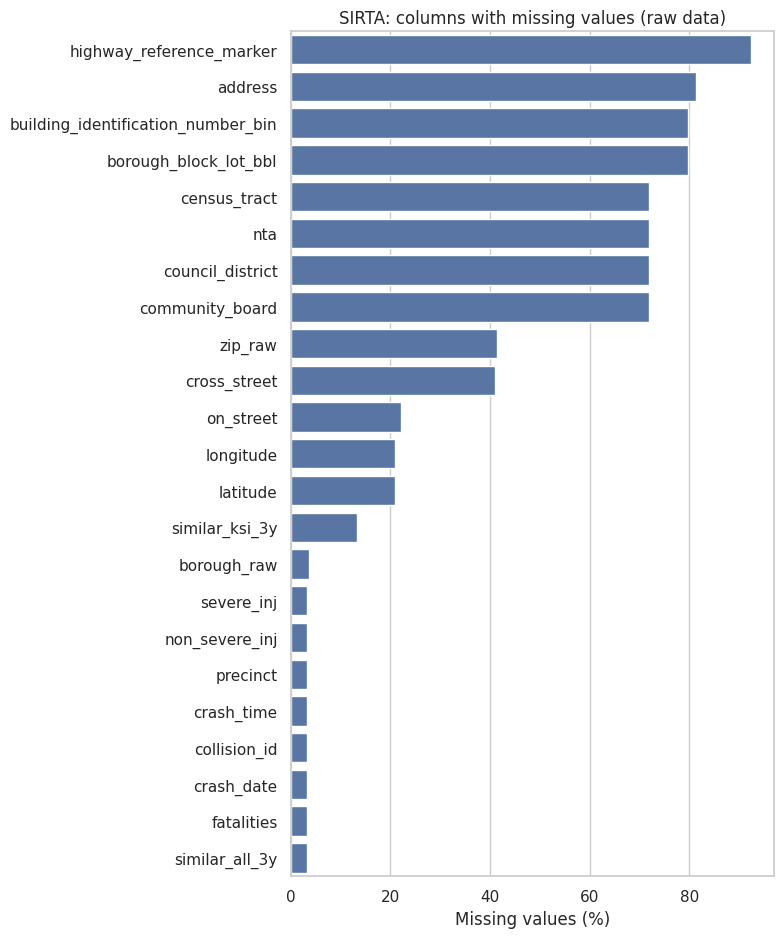

,zip_raw,latitude,community_board,census_tract,nta
missing % by year,,,,,
2022,83.7,11.0,83.5,83.5,83.5
2023,31.9,18.5,82.5,82.5,82.5
2024,30.0,33.8,63.4,63.4,63.4
2025,19.7,11.9,79.3,79.3,79.3
2026,26.0,12.4,50.4,50.6,50.6


In [65]:
missing = pd.DataFrame({"missing_n": df.isna().sum(), "missing_pct": df.isna().mean() * 100}
                       ).sort_values("missing_pct", ascending=False)
display(missing[missing.missing_n > 0])

top = missing[missing.missing_n > 0]
fig, ax = plt.subplots(figsize=(8, 0.35 * len(top) + 1.5))
sns.barplot(x=top.missing_pct, y=top.index, color="#4C72B0", ax=ax)
ax.set_xlabel("Missing values (%)"); ax.set_ylabel("")
ax.set_title("SIRTA: columns with missing values (raw data)")
plt.tight_layout(); plt.show()

# Missing geography by year: is the problem constant or concentrated in some years?
tmp = df.assign(year=pd.to_datetime(df["crash_date"], format="%m/%d/%Y", errors="coerce").dt.year.astype("Int64"))
tmp = tmp.dropna(subset=["collision_id"])
geo_cols = ["zip_raw", "latitude", "community_board", "census_tract", "nta"]
display(tmp.groupby("year")[geo_cols].agg(lambda s: s.isna().mean() * 100).round(1)
        .rename_axis("missing % by year"))

###  Duplicates

In [66]:
blank_rows = df["collision_id"].isna()
valid_ids = df[~blank_rows]
print(f"Fully identical rows:                 {df.duplicated().sum():,}")
print(f"Blank rows (no Collision ID):         {blank_rows.sum():,}")
print(f"Repeated Collision IDs (non-blank):   {valid_ids.duplicated(subset='collision_id').sum():,}")

Fully identical rows:                 3
Blank rows (no Collision ID):         444
Repeated Collision IDs (non-blank):   1


### Outliers


,min,median,p99,max,iqr_upper_fence,n_above_fence,n_negative
column,,,,,,,
non_severe_inj,0.0,0.0,4.0,19.0,0.0,2172,0
severe_inj,0.0,1.0,3.0,7.0,1.0,824,0
fatalities,0.0,0.0,1.0,5.0,0.0,1047,0


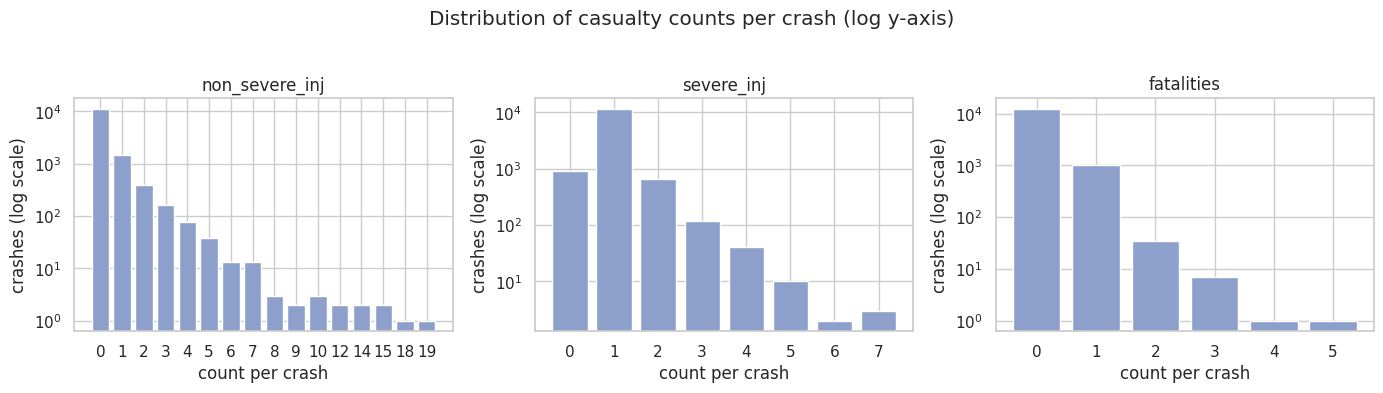

Crashes with severe injuries + deaths > 20: 0
Crashes with zero severe injuries AND zero deaths: 0


,collision_id,crash_date,borough_raw,severe_inj,fatalities,on_street
939,4523317.0,04/28/2022,Manhattan,7.0,0.0,NaN
3454,4584581.0,11/25/2022,Staten Island,7.0,0.0,NaN
6950,4691570.0,12/30/2023,Staten Island,7.0,0.0,RICHMOND ROAD
10348,4856579.0,11/06/2025,NaN,6.0,0.0,BROOKVILLE BLVD
12979,83126075.0,04/29/2026,Brooklyn,6.0,0.0,BELT PARKWAY


In [67]:
def iqr_bounds(series, k=1.5):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

count_cols = ["non_severe_inj", "severe_inj", "fatalities"]
rows = []
for c in count_cols:
    s = pd.to_numeric(df[c], errors="coerce").dropna()
    lo, hi = iqr_bounds(s)
    rows.append({"column": c, "min": s.min(), "median": s.median(), "p99": s.quantile(0.99), "max": s.max(),
                 "iqr_upper_fence": hi, "n_above_fence": int((s > hi).sum()), "n_negative": int((s < 0).sum())})
display(pd.DataFrame(rows).set_index("column"))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, c in zip(axes, count_cols):
    vc = pd.to_numeric(df[c], errors="coerce").value_counts().sort_index()
    ax.bar(vc.index.astype(int).astype(str), vc.values, color="#8DA0CB")
    ax.set_yscale("log"); ax.set_title(c); ax.set_xlabel("count per crash"); ax.set_ylabel("crashes (log scale)")
plt.suptitle("Distribution of casualty counts per crash (log y-axis)", y=1.03)
plt.tight_layout(); plt.show()

tot = (pd.to_numeric(df["severe_inj"], errors="coerce").fillna(0) + pd.to_numeric(df["fatalities"], errors="coerce").fillna(0))
print(f"Crashes with severe injuries + deaths > {MAX_CASUALTIES_PER_CRASH}: {(tot > MAX_CASUALTIES_PER_CRASH).sum()}")
print(f"Crashes with zero severe injuries AND zero deaths: {((tot == 0) & df['collision_id'].notna()).sum()}")
display(df.assign(ksi=tot).nlargest(5, "ksi")[["collision_id", "crash_date", "borough_raw", "severe_inj", "fatalities", "on_street"]])

###  Inconsistent data
Checks: borough spellings, ZIP formats, coordinates outside NYC, unparseable dates and times, community-board validity , and whether the community board agrees with the borough.

In [68]:
valid = df.dropna(subset=["collision_id"]).copy()

print("Borough values:"); display(valid["borough_raw"].value_counts(dropna=False))

print("ZIP string lengths:"); display(valid["zip_raw"].astype(str).str.extract(r"(\d+)")[0].str.len().value_counts(dropna=False))

lat, lon = pd.to_numeric(valid["latitude"], errors="coerce"), pd.to_numeric(valid["longitude"], errors="coerce")
outside = (~lat.between(*NYC_LAT_RANGE) | ~lon.between(*NYC_LON_RANGE)) & lat.notna() & lon.notna()
print(f"\nCoordinates outside NYC bounding box: {outside.sum():,} | (0,0) coordinates: {((lat == 0) | (lon == 0)).sum():,}")

dates = pd.to_datetime(valid["crash_date"], format="%m/%d/%Y", errors="coerce")
print(f"\nUnparseable crash dates: {dates.isna().sum():,} | range: {dates.min():%Y-%m-%d} -> {dates.max():%Y-%m-%d} "
      f"| future dates: {(dates > pd.Timestamp.today()).sum():,}")

hhmm = valid["crash_time"].astype("string").str.extract(r"^(\d{1,2}):(\d{2})")
print(f"Crash times not in HH:MM format: {hhmm[0].isna().sum():,} | hours outside 0-23: {(pd.to_numeric(hhmm[0]) > 23).sum():,}")

cb = normalize_community_board(valid["community_board"])
raw_cb = pd.to_numeric(valid["community_board"], errors="coerce")
print(f"\nCommunity board: missing = {raw_cb.isna().sum():,} | present but invalid (e.g. park areas) = {(raw_cb.notna() & cb.isna()).sum():,}")
boro_from_cb = (cb // 100).map(BOROUGH_CODE)
boro_clean = valid["borough_raw"].astype(str).str.strip().str.upper().map(BOROUGH_MAP)
print(f"Community board disagrees with the reported borough: {(cb.notna() & boro_clean.notna() & (boro_from_cb != boro_clean)).sum():,}")
print(f"Borough missing but derivable from community board: {(boro_clean.isna() & boro_from_cb.notna()).sum():,}")

Borough values:


,count
borough_raw,
Brooklyn,3954
Queens,3282
Manhattan,2733
Bronx,2617
Staten Island,669
NaN,55


ZIP string lengths:


,count
0,
5.0,8072
NaN,5238



Coordinates outside NYC bounding box: 0 | (0,0) coordinates: 0

Unparseable crash dates: 0 | range: 2022-01-01 -> 2026-06-30 | future dates: 0
Crash times not in HH:MM format: 0 | hours outside 0-23: 0

Community board: missing = 9,883 | present but invalid (e.g. park areas) = 84
Community board disagrees with the reported borough: 104
Borough missing but derivable from community board: 10


### Key finding: location is missing mostly for FATAL crashes
Before choosing an integration key we measure how complete each location field is, **separately for fatal and non-fatal crashes**.

,n_crashes,Community board,Coordinates,ZIP,Census tract,Police precinct,Borough
crash_type,,,,,,,
Fatal crash,1047,3.5,19.7,49.2,3.5,100.0,99.4
Non-fatal serious-injury crash,12263,27.6,86.9,61.6,27.6,100.0,99.6


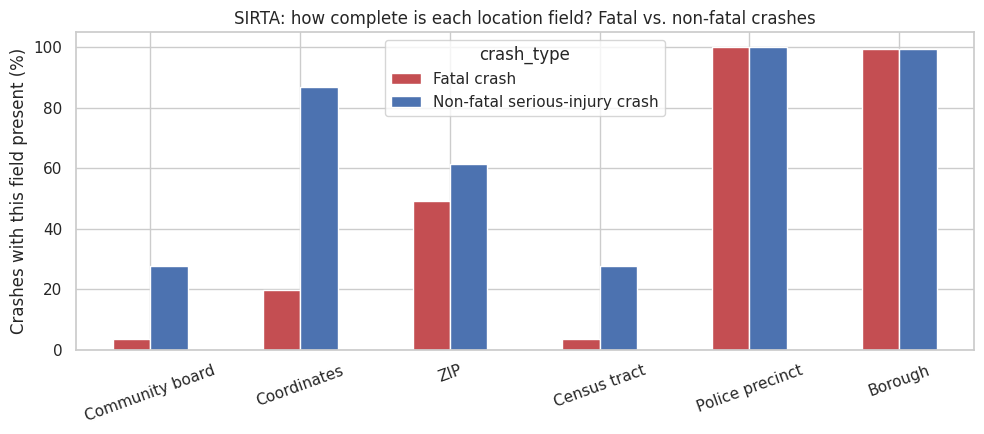

In [69]:
located = df.dropna(subset=["collision_id"]).copy()
located["crash_type"] = np.where(pd.to_numeric(located["fatalities"], errors="coerce").fillna(0) > 0,
                                 "Fatal crash", "Non-fatal serious-injury crash")
coverage_fields = {"community_board": "Community board", "latitude": "Coordinates", "zip_raw": "ZIP",
                   "census_tract": "Census tract", "precinct": "Police precinct", "borough_raw": "Borough"}
coverage = pd.DataFrame({label: located.groupby("crash_type")[col].apply(lambda s: s.notna().mean() * 100)
                         for col, label in coverage_fields.items()}).round(1)
coverage.insert(0, "n_crashes", located.groupby("crash_type").size())
display(coverage)

ax = coverage.drop(columns="n_crashes").T.plot(kind="bar", figsize=(10, 4.5), color=["#C44E52", "#4C72B0"])
ax.set_ylabel("Crashes with this field present (%)"); ax.set_ylim(0, 105); ax.tick_params(axis="x", rotation=20)
ax.set_title("SIRTA: how complete is each location field? Fatal vs. non-fatal crashes")
plt.tight_layout(); plt.show()

**Problem statement**
- only about 24% of crashes have a community board, and the gap is not random. Fatal crashes almost never carry a community board, census tract or coordinates. Only **borough** and **police precinct** are (nearly) complete for every crash.

##  Cleaning and standardization

### Decisions

| Issue | Decision | Why / alternative |
|---|---|---|
| Column names | `snake_case` + short canonical names (`severe_inj`, `fatalities`, `community_board`, ...) | Same style as the housing notebook, so Members 3, 5 and 6 get stable names. |
| Blank "orphan" rows (no Collision ID) | **Drop** | They have no date, location or counts, so there is nothing to impute. |
| Repeated Collision ID | Keep the first row | One row must equal one crash, otherwise severity is double counted. |
| Collision ID type | Convert float -> integer -> string | A float ID like `4492364.0` would break joins and lookups. |
| Dates / times | Parse `MM/DD/YYYY`; invalid -> **drop** the row. Extract `hour`, `weekday`, `is_weekend`, `year_month` | A crash that cannot be placed in time cannot be integrated. `year_month` is the planned temporal key. |
| Casualty counts | Numeric; negative -> missing; all three missing -> drop; otherwise missing -> 0 | A crash row is only in this dataset if someone was seriously hurt, so a single missing count most plausibly means 0. |
| `ksi` | `severe_inj + fatalities` | Standard road-safety measure (killed or seriously injured). |
| Extreme crashes | **Keep**, flag with `is_extreme_crash` (> 20 KSI) | Real mass-casualty events. Removing them would hide the worst crashes. IQR is degenerate for small counts, so a domain rule is used. |
| Borough | Upper-case + `BOROUGH_MAP`; if missing, derive from the community-board digit | Same categories as housing (needed for the join). Deriving it from the board is deterministic, not a guess. |
| Community board | Valid residential CD codes only (borough digit + CD 01..max). Park / joint-interest codes and codes that contradict the borough -> missing | CD is the integration key for my RQs. Invalid codes would create CDs that don't exist in housing. |
| ZIP | 5 digits inside 10001-11697, else missing. **Not imputed here** | Guessing a ZIP would misplace crashes. Member 3 decides whether to assign a ZIP from coordinates. |
| Coordinates | Outside the NYC bounding box -> missing; add `has_coordinates` | Rows kept: the CD/borough integration does not need coordinates. |
| Street names | Trim + upper case | Consistent text for the search mode on the website. |
| Council district | Numeric, valid values 1-51 only | Second shared geography with housing (used for a robustness check of RQ1). |
| `similar_ksi_3y` | Kept as a number | Official definition: deaths and severe injuries from crashes of the same type at the same location in the past 3 years. It describes the *location's history*, not the crash itself. |
| Missing location on fatal crashes | **Not imputed in cleaning.** Only flagged (`has_coordinates`); handled in section 7 | Imputing a district at cleaning time would hide the problem. The pattern is documented in 4.5. |
| Window | Keep crashes from `PANEL_START` | Matches the housing analysis window. |
| Columns kept | Only those needed for the story (see code) | BIN/BBL and highway marker are mostly empty and not used. |
| Near-duplicate reports | Drop the later report when date, minute, coordinates, casualties and streets match | Same crash entered twice; rows without coordinates are never dropped this way |
| Street names | Trim + upper case; standardize suffixes at the end of the name (AVE→AVENUE, ST→STREET, ...) | Consistent text for the website's search mode |

In [70]:
# Returns the cleaned dataset and a record of the changes made during cleaning.
def clean_sirta(raw):
    log = []
    def record(step, before, after, note=""):
        log.append({"step": step, "rows_before": before, "rows_after": after, "note": note})

    s = standardize_columns(raw)
    required = ["collision_id", "crash_date", "crash_time", "borough_raw", "non_severe_inj", "severe_inj",
                "fatalities", "latitude", "longitude", "zip_raw", "community_board"]
    absent = [c for c in required if c not in s.columns]
    assert not absent, f"SIRTA columns not found: {absent}. Compare with sirta_raw.columns."

    # Rows without collision_id
    n = len(s)
    s = s.dropna(subset=["collision_id"])
    record("drop rows without Collision ID", n, len(s), "blank orphan rows")
    s["collision_id"] = pd.to_numeric(s["collision_id"], errors="coerce")
    s = s.dropna(subset=["collision_id"])
    s["collision_id"] = s["collision_id"].astype("int64").astype(str)       # 9.0 -> "9"

    # Duplicates
    n = len(s)
    s = s.drop_duplicates(subset="collision_id", keep="first")
    record("one row per Collision ID", n, len(s))

    #  Dates and times
    d = pd.to_datetime(s["crash_date"], format="%m/%d/%Y", errors="coerce")
    s["crash_date"] = d.fillna(pd.to_datetime(s["crash_date"], errors="coerce"))
    n = len(s)
    s = s.dropna(subset=["crash_date"])
    s = s[s["crash_date"] <= pd.Timestamp.today()]
    record("drop rows without a valid (non-future) crash date", n, len(s))
    s["year"] = s["crash_date"].dt.year.astype("Int64")
    s["month"] = s["crash_date"].dt.month.astype("Int64")
    s["year_month"] = s["crash_date"].dt.strftime("%Y-%m")                  # temporal join key
    s["weekday"] = s["crash_date"].dt.day_name()
    s["is_weekend"] = s["crash_date"].dt.dayofweek >= 5
    hour = pd.to_numeric(s["crash_time"].astype("string").str.extract(r"^(\d{1,2}):")[0], errors="coerce")
    s["hour"] = hour.where(hour.between(0, 23)).astype("Int64")
    s["is_midnight_record"] = s["crash_time"].astype("string").str.strip().eq("00:00")   # possible 'time unknown' default

    # Casualty counts
    for c in ["non_severe_inj", "severe_inj", "fatalities"]:
        s[c] = pd.to_numeric(s[c], errors="coerce")
        s.loc[s[c] < 0, c] = np.nan
    n = len(s)
    s = s.dropna(subset=["non_severe_inj", "severe_inj", "fatalities"], how="all")
    record("drop rows with no casualty count at all", n, len(s))
    s[["non_severe_inj", "severe_inj", "fatalities"]] = s[["non_severe_inj", "severe_inj", "fatalities"]].fillna(0).astype(int)
    s["ksi"] = s["severe_inj"] + s["fatalities"]                            # killed or seriously injured
    s["is_fatal"] = s["fatalities"] > 0
    s["is_extreme_crash"] = s["ksi"] > MAX_CASUALTIES_PER_CRASH             # flagged, not removed

    # Borough + community board (these two must agree)
    s["borough"] = s["borough_raw"].astype(str).str.strip().str.upper().replace({"NAN": np.nan}).map(BOROUGH_MAP)
    cb = normalize_community_board(s["community_board"])
    boro_from_cb = (cb // 100).map(BOROUGH_CODE)
    filled = int((s["borough"].isna() & boro_from_cb.notna()).sum())
    s["borough"] = s["borough"].fillna(boro_from_cb)    #If the borough is missing but the community board is valid, derive the borough from the community board
    conflict = cb.notna() & s["borough"].notna() & (boro_from_cb != s["borough"])
    s["community_board"] = cb.mask(conflict)                                # conflicting? -> missing
    record("borough / community board consistency", len(s), len(s),
           f"{filled} boroughs derived from community board; {int(conflict.sum())} contradictory boards set to missing")

    # ZIP, coordinates, other geography
    zip5 = s["zip_raw"].astype(str).str.extract(r"(\d{5})")[0]
    s["zip_reported"] = zip5.where(pd.to_numeric(zip5, errors="coerce").between(10001, 11697))
    for c in ["latitude", "longitude"]:
        s[c] = pd.to_numeric(s[c], errors="coerce")
    bad_xy = ~(s["latitude"].between(*NYC_LAT_RANGE) & s["longitude"].between(*NYC_LON_RANGE))
    s.loc[bad_xy, ["latitude", "longitude"]] = np.nan                                  #outsude range? marked missing
    s["has_coordinates"] = s[["latitude", "longitude"]].notna().all(axis=1)
    s["census_tract"] = s["census_tract"].astype("string").str.replace(r"\.0$", "", regex=True)
    for c in ["precinct", "similar_ksi_3y"]:
        s[c] = pd.to_numeric(s[c], errors="coerce").astype("Int64")
    council = pd.to_numeric(s["council_district"], errors="coerce")
    s["council_district"] = council.where(council.between(1, 51)).astype("Int64")      # NYC has 51 council districts

    # Text columns
    for c in ["on_street", "cross_street"]:
        s[c] = s[c].astype("string").str.strip().str.upper()
        s[c] = s[c].str.replace(STREET_SUFFIX_PATTERN, lambda m: STREET_SUFFIX[m.group(1)], regex=True)
    # Near-duplicate reports: same minute, place and casualties but a different Collision ID
    n = len(s)
    has_xy = s["latitude"].notna() & s["longitude"].notna()        # rows WITHOUT coordinates are never treated as duplicates
    dup_key = ["crash_date", "crash_time", "latitude", "longitude", "non_severe_inj", "severe_inj",
               "fatalities", "on_street", "cross_street"]
    s = s[~(has_xy & s.duplicated(subset=dup_key, keep="first"))]
    record("drop near-duplicate reports (same minute, place, casualties)", n, len(s))

    # Analysis window
    n = len(s)
    s = s[s["year_month"] >= PANEL_START]
    record(f"keep crashes from {PANEL_START} onward", n, len(s))

    keep = ["collision_id", "crash_date", "year", "month", "year_month", "weekday", "is_weekend", "hour",
            "borough", "community_board", "council_district", "precinct", "zip_reported", "census_tract", "nta",
            "latitude", "longitude", "has_coordinates", "on_street", "cross_street",
            "non_severe_inj", "severe_inj", "fatalities", "ksi", "is_fatal", "is_extreme_crash", "similar_ksi_3y", "is_midnight_record"]
    return s[keep].reset_index(drop=True), pd.DataFrame(log)


sirta_clean, sirta_log = clean_sirta(sirta_raw)
display(sirta_log)
print(f"Raw rows: {len(sirta_raw):,}  ->  clean rows: {len(sirta_clean):,}")
sirta_clean.head()

,step,rows_before,rows_after,note
0,drop rows without Collision ID,13754,13310,blank orphan rows
1,one row per Collision ID,13310,13309,
2,drop rows without a valid (non-future) crash date,13309,13309,
3,drop rows with no casualty count at all,13309,13309,
4,borough / community board consistency,13309,13309,10 boroughs derived from community board; 104 ...
5,"drop near-duplicate reports (same minute, plac...",13309,13307,
6,keep crashes from 2022-01 onward,13307,13307,


Raw rows: 13,754  ->  clean rows: 13,307


,collision_id,crash_date,year,month,year_month,weekday,is_weekend,hour,borough,community_board,council_district,precinct,zip_reported,census_tract,nta,latitude,longitude,has_coordinates,on_street,cross_street,non_severe_inj,severe_inj,fatalities,ksi,is_fatal,is_extreme_crash,similar_ksi_3y,is_midnight_record
0,4492364,2022-01-01,2022,1,2022-01,Saturday,True,1,BRONX,<NA>,<NA>,46,NaN,<NA>,NaN,40.858707,-73.90370,True,JEROME AVENUE,EAST 183 STREET,1,1,0,1,False,False,0,False
1,4491159,2022-01-01,2022,1,2022-01,Saturday,True,4,BRONX,<NA>,<NA>,46,NaN,<NA>,NaN,NaN,NaN,False,JEROME AVENUE,<NA>,0,1,0,1,False,False,0,False
2,4491487,2022-01-01,2022,1,2022-01,Saturday,True,5,BRONX,212,12,47,NaN,372,BX1201,40.871550,-73.86428,True,<NA>,<NA>,0,1,0,1,False,False,0,False
3,4491223,2022-01-01,2022,1,2022-01,Saturday,True,10,BRONX,<NA>,<NA>,43,NaN,<NA>,NaN,40.823673,-73.87233,True,BRONX RIVER PARKWAY,<NA>,0,1,0,1,False,False,0,False
4,4491418,2022-01-01,2022,1,2022-01,Saturday,True,20,BRONX,<NA>,<NA>,49,NaN,<NA>,NaN,40.863945,-73.86452,True,BOSTON ROAD,WALLACE AVENUE,0,1,0,1,False,False,0,False


## Validate the cleaning
We compare before and after and check that the cleaned data make sense

,check,after_cleaning
0,Boroughs (should be 5),5
1,Missing borough (%),0.34
2,Valid community boards (distinct),59
3,Missing community board (%),75.67
4,Missing reported ZIP (%),39.67
5,Missing coordinates (%),18.34
6,Duplicate Collision IDs,0
7,Crashes with KSI = 0,0
8,Extreme crashes (flagged),0
9,Date range,2022-01-01 to 2026-06-30


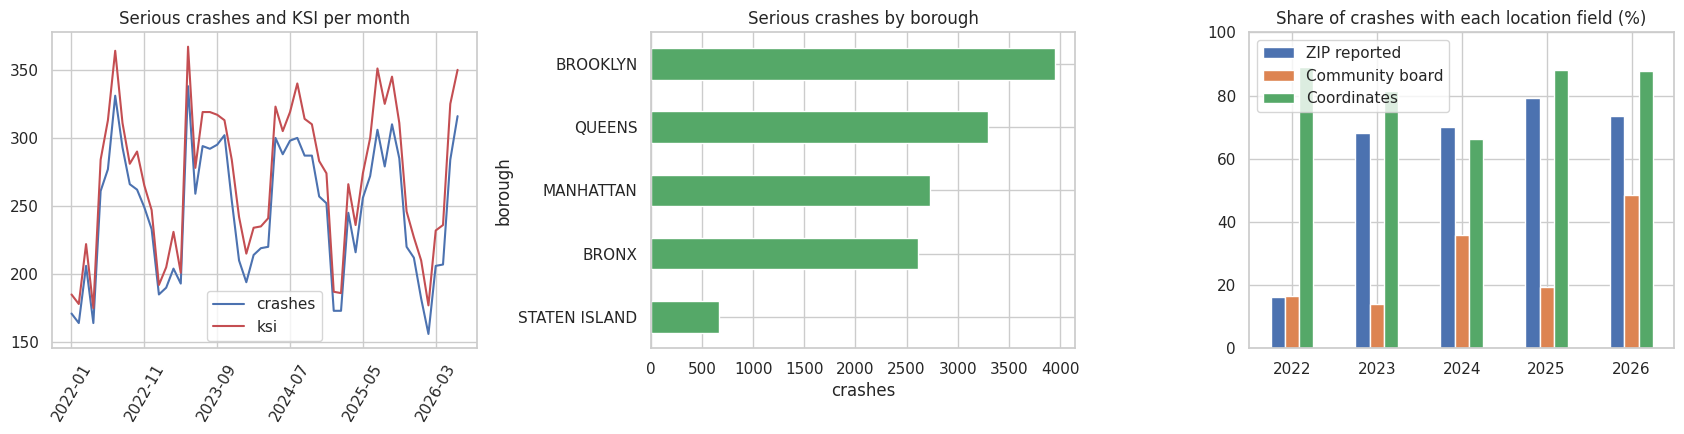

In [71]:
checks = pd.DataFrame({
    "check": ["Boroughs (should be 5)", "Missing borough (%)", "Valid community boards (distinct)", "Missing community board (%)",
              "Missing reported ZIP (%)", "Missing coordinates (%)", "Duplicate Collision IDs",
              "Crashes with KSI = 0", "Extreme crashes (flagged)", "Date range"],
    "after_cleaning": [
        sirta_clean["borough"].nunique(),
        round(sirta_clean["borough"].isna().mean() * 100, 2),
        sirta_clean["community_board"].nunique(),
        round(sirta_clean["community_board"].isna().mean() * 100, 2),
        round(sirta_clean["zip_reported"].isna().mean() * 100, 2),
        round((~sirta_clean["has_coordinates"]).mean() * 100, 2),
        int(sirta_clean["collision_id"].duplicated().sum()),
        int((sirta_clean["ksi"] == 0).sum()),
        int(sirta_clean["is_extreme_crash"].sum()),
        f"{sirta_clean['crash_date'].min():%Y-%m-%d} to {sirta_clean['crash_date'].max():%Y-%m-%d}",
    ],
})
display(checks)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

# crashes per month: shows the window and whether the last month is incomplete
monthly = sirta_clean.groupby("year_month").agg(crashes=("collision_id", "size"), ksi=("ksi", "sum"))
monthly.plot(ax=axes[0], color=["#4C72B0", "#C44E52"])
axes[0].set_title("Serious crashes and KSI per month"); axes[0].set_xlabel(""); axes[0].tick_params(axis="x", rotation=60)

# crashes by borough
sirta_clean["borough"].value_counts().sort_values().plot(kind="barh", ax=axes[1], color="#55A868")
axes[1].set_title("Serious crashes by borough"); axes[1].set_xlabel("crashes")

# coordinates are the most complete field.
cov = (sirta_clean.assign(zip_ok=sirta_clean["zip_reported"].notna(), cb_ok=sirta_clean["community_board"].notna(),
                          xy_ok=sirta_clean["has_coordinates"])
       .groupby("year")[["zip_ok", "cb_ok", "xy_ok"]].mean() * 100)
cov.columns = ["ZIP reported", "Community board", "Coordinates"]
cov.plot(kind="bar", ax=axes[2]); axes[2].set_title("Share of crashes with each location field (%)")
axes[2].set_xlabel(""); axes[2].set_ylim(0, 100); axes[2].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

In [72]:
raw_valid = sirta_raw.dropna(subset=["Collision ID"])
print(f"Crashes recorded exactly at 00:00: {(raw_valid['Crash Time'].astype(str).str.strip() == '00:00').mean():.1%}")
print((sirta_clean["hour"].value_counts(normalize=True).sort_index() * 100).round(1).head(4))

ids = sirta_clean["collision_id"].astype("int64")
print("Collision IDs above 10 million, by year:"); print((ids > 10_000_000).groupby(sirta_clean["year"]).sum())

Crashes recorded exactly at 00:00: 1.4%
hour
0    4.9
1    2.7
2    2.3
3    2.2
Name: proportion, dtype: Float64
Collision IDs above 10 million, by year:
year
2022      0
2023      0
2024      0
2025      0
2026    797
Name: collision_id, dtype: int64


Exactly 186 crashes (1.4%) are recorded at 00:00, far more than any typical single minute would hold. None of them is fatal and 95% have coordinates, which is consistent with default time entries. Without them, hour 0 holds 3.6% of crashes, a smooth decline between hour 23 (4.2%) and hour 1 (2.7%). The rows are kept and flagged (`is_midnight_record`) and tested in a sensitivity check for RQ2. Collision IDs above 10 million appear only from 2026 (797 crashes), probably a system change.

In [73]:
xy = sirta_clean.dropna(subset=["latitude", "longitude"])
mask = xy.duplicated(subset=["crash_date", "hour", "latitude", "longitude"], keep=False)
display(xy[mask].sort_values(["crash_date", "hour"])[["collision_id", "crash_date", "hour", "latitude", "longitude",
                                                      "on_street", "severe_inj", "fatalities"]])

,collision_id,crash_date,hour,latitude,longitude,on_street,severe_inj,fatalities
3949,4633628,2023-05-07,7,40.764110,-73.98850,WEST 51 STREET,1,0
3965,4633990,2023-05-07,7,40.764110,-73.98850,WEST 51 STREET,1,0
8843,4829959,2025-07-21,1,40.767963,-73.91168,25 AVENUE,1,0
8927,4832191,2025-07-21,1,40.767963,-73.91168,25 AVENUE,1,0
9251,4839841,2025-09-05,12,40.760006,-73.96652,<NA>,1,0
9255,4839904,2025-09-05,12,40.760006,-73.96652,<NA>,1,0
9337,4842169,2025-09-11,13,40.678318,-73.94692,NEW YORK AVENUE,1,0
9367,4842762,2025-09-11,13,40.678318,-73.94692,ATLANTIC AVENUE,1,0


Before cleaning, 6 pairs of crashes (12 rows) shared the same date, hour and coordinates. Two later reports matched the first one on minute, coordinates, casualty counts and street names, so they were treated as the same crash entered twice and dropped. The 4 pairs that remain are separate crashes: two pairs were recorded in different minutes of the same hour, one pair has different cross streets, and one pair is on different streets. Rows without coordinates are never treated as duplicates. The effect is negligible (2 of 13,309 crashes).

In [74]:
sirta_clean.to_csv(SIRTA_CLEAN_FILE, index=False)
print("Saved", SIRTA_CLEAN_FILE, sirta_clean.shape)

# from google.colab import files; files.download(SIRTA_CLEAN_FILE)

Saved sirta_clean.csv (13307, 28)


### Cleaning findings
The 2026-10-29 snapshot of SIRTA had 13,754 rows and 23 columns. We removed 444 blank rows without a Collision ID, 1 repeated Collision ID and 2 near-duplicate reports, leaving 13,307 crashes from 2022-01-01 to 2026-06-30. All dates and times were valid, no coordinates fell outside NYC, and no casualty counts were negative.

After cleaning, 24.3% of crashes have a community board, 60.3% a reported ZIP and 81.7% coordinates, so coordinates are the most complete location field. Coverage differs sharply by crash type: in the raw data, fatal crashes have a community board in 3.5% of cases and coordinates in 19.7%, versus 27.6% and 86.9% for non-fatal crashes. Only borough and police precinct are complete for every crash.

Of the reported community boards, 84 were not residential districts (park or joint-interest areas) and 104 contradicted the reported borough, so they were set to missing. 10 missing boroughs were derived from the board, leaving 45 crashes (0.34%) without a borough.

Casualty counts are small and skewed (at most 7 severe injuries and 19 non-severe injuries in one crash). The IQR rule flagged 2,172 / 824 / 1,047 crashes (non-severe injuries / severe injuries / fatalities), because the fences sit at 0 or 1. We used a domain rule instead: no crash exceeds 20 killed or seriously injured, so nothing was removed or flagged as extreme.

## DRAFT: prototype integration for my research questions (community district)

> **temporary.** The official integration is Member 3's responsibility. This prototype only lets me develop and test my research questions. My questions need these columns: crash-level `collision_id, community_district, council_district_final, hour, weekday, is_weekend, ksi, similar_ksi_3y` and district-level `new_units, new_filings`.

**Join level: community district (59 areas), 2022-01 to the last complete month.**

**How crashes get a district:** if SIRTA reports a valid community board we keep it. Otherwise, if the crash has coordinates, we take the district of the **nearest housing filing within `ASSIGN_MAX_M` metres** (housing filings carry both coordinates and community board). The same is done for council district. We **validate** the method on crashes whose district is reported, and record where each district came from (`community_district_source`).

**Alternatives considered:** (a) official community-district boundary polygons (more accurate, but needs an extra boundary file and a spatial join; a good choice for Member 3); (b) ZIP (Member 1's approach, ~40% missing in SIRTA); (c) borough x month (complete for all crashes including fatal ones, but only 5 areas).

**Housing side:** new-building filings and proposed units per district. A district with crashes but no new-building filing gets **0**, a true zero because the housing data covers the whole city.

In [75]:
housing = pd.read_csv(HOUSING_CLEAN_FILE, low_memory=False)      # needs community_board, council_district, latitude, longitude

END_MONTH = str(sirta_clean["crash_date"].max().to_period("M") )
print(f"Analysis window: {PANEL_START} to {END_MONTH}")

# ---- Housing side
housing["community_board"] = normalize_community_board(housing["community_board"])
housing["council_district"] = pd.to_numeric(housing["council_district"], errors="coerce")
housing.loc[~housing["council_district"].between(1, 51), "council_district"] = np.nan
new_buildings = housing[(housing["is_new_building"] == True) & housing["year_month"].between(PANEL_START, END_MONTH)]
housing_cd = (new_buildings.dropna(subset=["community_board"]).groupby("community_board")
              .agg(new_filings=("is_new_building", "size"), new_units=("proposed_dwelling_units", "sum"))
              .reset_index())
housing_cn = (new_buildings.dropna(subset=["council_district"]).groupby("council_district")
              .agg(new_filings=("is_new_building", "size"), new_units=("proposed_dwelling_units", "sum"))
              .reset_index())

# ---- Assign a district to crashes from the nearest housing filing
def to_xy_metres(lat, lon):
    """Simple local projection (good enough inside NYC) so distances are in metres."""
    lat, lon = np.asarray(lat, dtype=float), np.asarray(lon, dtype=float)
    return np.column_stack([(lon + 74.0) * 111_320 * np.cos(np.radians(40.7)), (lat - 40.7) * 110_540])

def assign_from_nearest_filing(crash_frame, value_col):
    """District code of the nearest housing filing within ASSIGN_MAX_M metres, else NA."""
    ref = housing.dropna(subset=["latitude", "longitude", value_col])          # reference = ALL filings, not only new buildings
    tree = cKDTree(to_xy_metres(ref["latitude"], ref["longitude"]))
    values = ref[value_col].to_numpy()
    out = pd.Series(pd.NA, index=crash_frame.index, dtype="Int64")
    sub = crash_frame.dropna(subset=["latitude", "longitude"])
    dist, idx = tree.query(to_xy_metres(sub["latitude"], sub["longitude"]), k=1, distance_upper_bound=ASSIGN_MAX_M)
    found = np.isfinite(dist)
    out.loc[sub.index[found]] = values[idx[found]].astype("int64")
    return out

crashes = sirta_clean[sirta_clean["year_month"].between(PANEL_START, END_MONTH)].copy()
crashes["crash_type"] = np.where(crashes["is_fatal"], "Fatal crash", "Non-fatal serious-injury crash")

for reported_col, ref_col, final_col in [("community_board", "community_board", "community_district"),
                                         ("council_district", "council_district", "council_district_final")]:
    reported = crashes[reported_col].astype("Int64")
    assigned = assign_from_nearest_filing(crashes, ref_col)

    # Validation: how often does the assigned value equal the REPORTED value?
    known = reported.notna() & assigned.notna()
    accuracy = (reported[known] == assigned[known]).mean()
    print(f"{final_col}: assigned for {known.sum() / reported.notna().sum():.1%} of crashes with a reported value, "
          f"correct for {accuracy:.1%} of those")

    crashes[final_col] = reported.fillna(assigned)
    crashes[final_col + "_source"] = np.select([reported.notna(), assigned.notna()],
                                               ["reported", "assigned from coordinates"], default="unassigned")

# ---- Coverage after assignment, split by fatal vs non-fatal (the honest picture)
source_table = (crashes.groupby("crash_type")["community_district_source"].value_counts(normalize=True)
                .unstack().mul(100).round(1))
source_table["n_crashes"] = crashes.groupby("crash_type").size()
display(source_table)

Analysis window: 2022-01 to 2026-06
community_district: assigned for 95.6% of crashes with a reported value, correct for 95.7% of those
council_district_final: assigned for 93.7% of crashes with a reported value, correct for 92.3% of those


community_district_source,assigned from coordinates,reported,unassigned,n_crashes
crash_type,,,,
Fatal crash,18.8,2.4,78.8,1046
Non-fatal serious-injury crash,61.0,26.2,12.8,12261


###  District-level table and post-integration cleaning

In [76]:
def district_table(frame, key):
    """One row per district: crash counts and the number of crashes at locations with a history of similar severe crashes."""
    g = frame.dropna(subset=[key]).copy()
    g["history_known"] = g["similar_ksi_3y"].notna()
    g["repeat_location"] = g["similar_ksi_3y"].fillna(0) > 0
    return (g.groupby(key).agg(crashes=("collision_id", "nunique"), severe_inj=("severe_inj", "sum"),
                               fatalities=("fatalities", "sum"), ksi=("ksi", "sum"),
                               history_known=("history_known", "sum"), repeat_location=("repeat_location", "sum"))
            .reset_index())

cd_panel = district_table(crashes, "community_district").merge(
    housing_cd.rename(columns={"community_board": "community_district"}), on="community_district", how="left")
cn_panel = district_table(crashes, "council_district_final").merge(
    housing_cn.rename(columns={"council_district": "council_district_final"}), on="council_district_final", how="left")

# ---- Post-integration cleaning
missing_before = int(cd_panel[["new_filings", "new_units"]].isna().sum().sum())
for panel in (cd_panel, cn_panel):
    panel[["new_filings", "new_units"]] = panel[["new_filings", "new_units"]].fillna(0)   # no new-building filing = true zero
    panel["repeat_share"] = panel["repeat_location"] / panel["history_known"]            # share of crashes at repeat-risk spots
    panel["log_new_units"] = np.log10(1 + panel["new_units"])
cd_panel["community_district"] = cd_panel["community_district"].astype(int)
cd_panel["borough"] = (cd_panel["community_district"] // 100).map(BOROUGH_CODE)
cd_panel["cd_label"] = cd_panel["borough"].map(BOROUGH_ABBR) + " " + (cd_panel["community_district"] % 100).astype(str).str.zfill(2)
cn_panel["council_district_final"] = cn_panel["council_district_final"].astype(int)

located_n = int(crashes["community_district"].notna().sum())
print(f"New missing values created by the join: {missing_before} (filled with 0, true zeros)")
print(f"Crashes with a district: {located_n:,} of {len(crashes):,} ({located_n / len(crashes):.1%}); "
      f"fatal crashes with a district: {crashes.loc[crashes.is_fatal, 'community_district'].notna().mean():.1%}")
print(f"Community districts in the panel: {len(cd_panel)} | council districts: {len(cn_panel)}")
display(cd_panel.sort_values("new_units", ascending=False).head(8))

New missing values created by the join: 0 (filled with 0, true zeros)
Crashes with a district: 10,915 of 13,307 (82.0%); fatal crashes with a district: 21.2%
Community districts in the panel: 59 | council districts: 51


,community_district,crashes,severe_inj,fatalities,ksi,history_known,repeat_location,new_filings,new_units,repeat_share,log_new_units,borough,cd_label
42,401,216,223,4,227,194,7,160,8845.0,0.036082,3.946747,QUEENS,QN 01
28,305,280,302,5,307,247,20,177,7276.0,0.080972,3.861952,BROOKLYN,BK 05
24,301,304,314,4,318,277,18,206,6863.0,0.064982,3.836577,BROOKLYN,BK 01
53,412,315,336,2,338,287,25,344,6431.0,0.087108,3.808346,QUEENS,QN 12
29,306,143,151,0,151,129,9,113,5774.0,0.069767,3.761552,BROOKLYN,BK 06
15,204,220,236,2,238,204,22,71,5660.0,0.107843,3.752893,BRONX,BX 04
18,207,182,189,5,194,167,25,96,5307.0,0.149701,3.724931,BRONX,BX 07
3,104,223,225,5,230,198,15,36,4636.0,0.075758,3.666237,MANHATTAN,MN 04


##  Research Question 1

**Do community districts with more new housing capacity have a larger share of their serious crashes at *repeat-risk locations*, meaning places where similar severe crashes already happened in the previous three years?**

 A location with a history of similar severe crashes is a known problem spot. If districts that are adding many new homes also have more of these chronic spots, the city can target street redesign where more people are about to arrive, instead of waiting for the next crash.

`similar_ksi_3y` (official definition: deaths and severe injuries from crashes of the same type at the same location in the past three years) is available for ~90% of crashes, **including fatal ones**. We use a **share** (repeat-risk crashes / located crashes), which also avoids the size effect: big districts have more of everything.

*Method:* For each community district, compare `log10(1 + new-building proposed units)` with the repeat-risk share. Districts with fewer than `MIN_CRASHES_PER_DISTRICT` located crashes are excluded (shares are unstable). Spearman rank correlation is used because counts are skewed.

*Caution:* only ~6% of crashes are at repeat-risk locations, so shares are noisy. Borough is a confounder (road type, density), so we also report correlations within boroughs.

In [77]:
rq1 = cd_panel[cd_panel["history_known"] >= MIN_CRASHES_PER_DISTRICT].copy()
rho, p = stats.spearmanr(rq1["new_units"], rq1["repeat_share"])
print(f"Spearman rho = {rho:.2f} (p = {p:.3f}) across {len(rq1)} community districts "
      f"(overall repeat-risk share = {rq1['repeat_location'].sum() / rq1['history_known'].sum():.1%})")

within = []
for boro, g in rq1.groupby("borough"):
    if len(g) >= 6:
        r, pv = stats.spearmanr(g["new_units"], g["repeat_share"])
        within.append({"borough": boro, "n_districts": len(g), "spearman_rho": round(r, 2), "p_value": round(pv, 3)})
display(pd.DataFrame(within))

fig1 = px.scatter(
    rq1, x="log_new_units", y="repeat_share", color="borough", size="history_known", hover_name="cd_label",
    hover_data={"new_units": ":,.0f", "new_filings": True, "history_known": True, "repeat_location": True,
                "log_new_units": False, "repeat_share": ":.1%"},
    labels={"log_new_units": "New housing capacity: log10(1 + proposed units in new buildings)",
            "repeat_share": "Share of crashes at repeat-risk locations", "borough": "Borough"},
    title=f"New housing vs. repeat-risk crash locations by community district (Spearman rho = {rho:.2f})",
)
fig1.add_hline(y=rq1["repeat_location"].sum() / rq1["history_known"].sum(), line_dash="dot", line_color="gray",
               annotation_text="City-wide share")
fig1.update_yaxes(tickformat=".0%")
fig1.update_layout(template="plotly_white", legend_title_text="Borough (bubble size = located crashes)")
fig1.show()

Spearman rho = 0.41 (p = 0.001) across 59 community districts (overall repeat-risk share = 6.9%)


,borough,n_districts,spearman_rho,p_value
0,BRONX,12,0.54,0.071
1,BROOKLYN,18,0.75,0.000
2,MANHATTAN,12,0.72,0.008
3,QUEENS,14,-0.40,0.154


### Robustness check: council districts
The same question at a different geography (51 council districts). If the result is similar, it does not depend on one boundary system.

In [78]:
rq1_cn = cn_panel[cn_panel["history_known"] >= MIN_CRASHES_PER_DISTRICT]
rho_cn, p_cn = stats.spearmanr(rq1_cn["new_units"], rq1_cn["repeat_share"])
print(f"Council districts:   Spearman rho = {rho_cn:.2f} (p = {p_cn:.3f}) across {len(rq1_cn)} districts")
print(f"Community districts: Spearman rho = {rho:.2f} (p = {p:.3f}) across {len(rq1)} districts")

fig1b = px.scatter(rq1_cn, x="log_new_units", y="repeat_share", size="history_known", hover_name="council_district_final",
                   hover_data={"new_units": ":,.0f", "history_known": True, "log_new_units": False, "repeat_share": ":.1%"},
                   labels={"log_new_units": "New housing capacity: log10(1 + proposed units in new buildings)",
                           "repeat_share": "Share of crashes at repeat-risk locations"},
                   title=f"Robustness: council districts (Spearman rho = {rho_cn:.2f})")
fig1b.update_yaxes(tickformat=".0%")
fig1b.update_layout(template="plotly_white")
fig1b.show()

Council districts:   Spearman rho = 0.39 (p = 0.004) across 51 districts
Community districts: Spearman rho = 0.41 (p = 0.001) across 59 districts


##  Research Question 2

**Do serious crashes happen at different times of the week in community districts with heavy new-housing activity than in districts with little?**

*Why it matters:* Construction and delivery traffic is concentrated on weekday daytime, while nightlife and speeding peak at night and on weekends. If higher-development districts show a different weekly rhythm, safety measures (work-zone enforcement vs. night-time speed control) should be timed differently.

*Method:* Split districts at the median of new-building units into **Lower** and **Higher development**. For each group, build an hour x weekday heatmap with each cell shown as a percentage of the group's crashes (so groups of different size are comparable). Then test two shares with a chi-square test: *night* crashes (22:00-05:59) and *weekday daytime* crashes (Mon-Fri, 07:00-17:59).

*Caution:* only crashes that could be placed in a district are used (fatal crashes are under-represented, see 4.5). Time of day is complete for every crash, so the pattern is reliable for the located subset, but the groups differ in many ways besides construction (density, nightlife, highways).

In [79]:
# Median split of districts by new-building units (rank first so ties don't break the split)
cd_panel["dev_tier"] = pd.qcut(cd_panel["new_units"].rank(method="first"), 2,
                               labels=["Lower development", "Higher development"])
tier_of_cd = cd_panel.set_index("community_district")["dev_tier"]

rq2_crashes = crashes.dropna(subset=["community_district", "hour"]).copy()
rq2_crashes["dev_tier"] = rq2_crashes["community_district"].astype(int).map(tier_of_cd)
rq2_crashes = rq2_crashes.dropna(subset=["dev_tier"])

DAY_ORDER = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
rq2_crashes["is_night"] = (rq2_crashes["hour"] >= 22) | (rq2_crashes["hour"] <= 5)
rq2_crashes["is_weekday_day"] = (~rq2_crashes["is_weekend"]) & rq2_crashes["hour"].between(7, 17)

def tier_heatmap(tier):
    """Weekday x hour grid as % of the tier's crashes."""
    sub = rq2_crashes[rq2_crashes["dev_tier"] == tier]
    grid = (sub.groupby(["weekday", "hour"]).size().unstack(fill_value=0)
            .reindex(index=DAY_ORDER, columns=range(24), fill_value=0))
    return grid / grid.values.sum() * 100

tiers = ["Lower development", "Higher development"]
grids = {tier: tier_heatmap(tier) for tier in tiers}
zmax = max(g.values.max() for g in grids.values())

fig2 = make_subplots(rows=1, cols=2, shared_yaxes=True, horizontal_spacing=0.04,
                     subplot_titles=[f"{tier} (n={int((rq2_crashes.dev_tier == tier).sum()):,} crashes)" for tier in tiers])
for i, tier in enumerate(tiers, start=1):
    fig2.add_trace(go.Heatmap(z=grids[tier].values, x=list(range(24)), y=DAY_ORDER, zmin=0, zmax=zmax,
                              colorscale="YlOrRd", showscale=(i == 2),
                              colorbar=dict(title="% of group's crashes"),
                              hovertemplate="%{y} %{x}:00<br>%{z:.2f}% of crashes<extra></extra>"), row=1, col=i)
    fig2.update_xaxes(title_text="Hour of day", dtick=3, row=1, col=i)
fig2.update_yaxes(autorange="reversed")
fig2.update_layout(template="plotly_white", height=430,
                   title="When do serious crashes happen? Weekly rhythm by level of new-housing activity")
fig2.show()

rows = []
for col, name in [("is_night", "Night (22:00-05:59)"), ("is_weekday_day", "Weekday daytime (Mon-Fri 07:00-17:59)")]:
    table = pd.crosstab(rq2_crashes["dev_tier"], rq2_crashes[col])
    chi2, pv, _, _ = stats.chi2_contingency(table)
    shares = rq2_crashes.groupby("dev_tier")[col].mean() * 100
    rows.append({"period": name, "lower_dev_%": shares["Lower development"], "higher_dev_%": shares["Higher development"],
                 "chi2": chi2, "p_value": pv})
display(pd.DataFrame(rows))

,period,lower_dev_%,higher_dev_%,chi2,p_value
0,Night (22:00-05:59),24.388790,23.351462,1.551160,0.212964
1,Weekday daytime (Mon-Fri 07:00-17:59),39.872789,39.326988,0.315409,0.574380


### Fatalities at borough level
Because fatal crashes rarely have a district, fatalities are shown only by borough and year, where coverage is ~100%.

In [80]:
borough_year = (sirta_clean[sirta_clean["year_month"].between(PANEL_START, END_MONTH)]
                .dropna(subset=["borough"]).groupby(["borough", "year"])
                .agg(crashes=("collision_id", "size"), fatalities=("fatalities", "sum"), ksi=("ksi", "sum")).reset_index())
borough_year["fatal_share"] = borough_year["fatalities"] / borough_year["ksi"]
fig3 = px.bar(borough_year, x="year", y="fatalities", color="borough", barmode="group",
              labels={"fatalities": "Deaths in serious crashes", "year": "Year", "borough": "Borough"},
              title="Deaths in serious crashes by borough and year (complete location field)")
fig3.update_layout(template="plotly_white")
fig3.show()

In [81]:
# Exports for the team (Member 3 integration check, Members 5-6 website)
crashes.to_csv("sirta_crashes_with_district.csv", index=False)
cd_panel.to_csv("rq_cd_panel.csv", index=False)
cn_panel.to_csv("rq_council_panel.csv", index=False)
rq2_crashes[["collision_id", "community_district", "borough", "dev_tier", "weekday", "hour", "year", "ksi", "fatalities"]]\
    .to_csv("rq2_crashes_by_tier.csv", index=False)
borough_year.to_csv("borough_year_fatalities.csv", index=False)
fig1.write_html("m2_rq1_scatter.html"); fig1b.write_html("m2_rq1_robustness_council.html")
fig2.write_html("m2_rq2_heatmap.html"); fig3.write_html("m2_borough_fatalities.html")
print("Exported 5 CSV files and 4 HTML charts.")

Exported 5 CSV files and 4 HTML charts.
